## Programa7.HoldOut

Noviembre 14, 2026

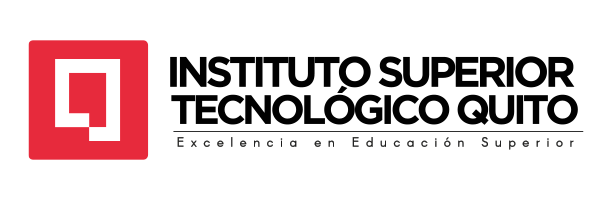

**Nombre:** Edgar Ulloa  
**Fecha:** *14-11-2026*    
**Link Repositorio:** https://github.com/eulloaitq/Fundamentos-de-Machine-Learning.git

## Método Hold-Out para clasificación con Iris
**Objetivo:** Comprender cómo se puede dividir un dataset para entrenamiento, validación y prueba, preparar sus atributos, comparar un clasificador de referencia con un modelo SVC y guardar el modelo entrenado.

**Aprendizaje supervisado:** Es una técnica en la que un algoritmo aprende a relacionar los atributos de entrada con unas etiquetas conocidas, en este trabajo las etiquetas corresponden a las especies de unas flores conocidas como Iris.

**Metodología:** Se utiliza el método Hold-Out, el cual consiste en separar los datos en subconjuntos para entrenar y evaluar un modelo con observaciones diferentes.

## Asignación del modelo entrenado
La instrucción model = svc permite asignar el clasificador SVC previamente entrenado a una variable denominada model, con esta asignación se facilita su posterior almacenamiento mediante la función pickle.dump(), sin necesidad de volver a entrenarlo.

In [9]:
#model = svc

## Importación de bibliotecas
Una biblioteca es un conjunto de codigos que reúne una serie de herramientas reutilizables para poder realizar operaciones sin tener que programarlas desde cero.

Para la realización de este trabajo se esta importando las siguientes bibliotecas:
- **numpy (np):** Realiza operaciones con arreglos numéricos; se utilizará para contar clases y redondear resultados.
- **sklearn.datasets:** Proporciona datasets de ejemplo, como Iris.
- **DummyClassifier:**  Clasificador sencillo que sirve como referencia para comparar modelos.
- **train_test_split():** Divide los datos y las etiquetas en subconjuntos aleatorios.
- **StandardScaler:** Transforma los atributos para que tengan una escala comparable.

In [10]:
import numpy as np
from sklearn import datasets
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## Carga del dataset Iris
El **dataset Iris** que se esta utilizando en este trabajo contiene 150 observaciones de flores, con cuatro atributos numéricos a saber: longitud y anchura de sépalo y pétalo y tres clases de especies.

**Funciones y atributos:** La función datasets.load_iris() carga el dataset; el atributo iris.target_names contiene los nombres de las especies.

In [11]:
# Carga de datos
iris = datasets.load_iris()
print(iris.target_names)

['setosa' 'versicolor' 'virginica']


Se muestran las tres especies de la flor Iris: *setosa*, *versicolor* y *virginica*.

## Exploración inicial de los datos
Antes de entrenar el modelo se debe comprobar cuántas observaciones y atributos existen y cómo se distribuyen las clases para detectar si no existen desequilibrios importantes.

- **iris.data:** Contiene la matriz de atributos; **iris.target:** Contiene las etiquetas de clase.
- **.shape:** Comando que devuelve las dimensiones de una matriz; **shape[0]** identifica las instancias y **shape[1]** los atributos.
- **set():** Comando que obtiene los valores de la clase que son diferentes.
- **np.unique(..., return_counts=True):** Comando que devuelve las clases distintas y el número de veces que aparece cada una.

In [12]:
# Mostrar características de la tabla de datos.
print("Tabla de datos: %d instancias y %d atributos" % (iris.data.shape[0], iris.data.shape[1]))
print("Valores de la clase:", set(iris.target))

# Cuantificamos el número de instancias que contiene el dataset por clase
valores, ocurrencias = np.unique(iris.target, return_counts=True)
print(valores, ocurrencias)

Tabla de datos: 150 instancias y 4 atributos
Valores de la clase: {np.int64(0), np.int64(1), np.int64(2)}
[0 1 2] [50 50 50]


El dataset de Iris contiene 150 registros, 4 atributos y 3 clases, con 50 registros por clase, demostrando que el dataset original está equilibrado.

## Partición externa Hold-Out: entrenamiento y prueba
El **conjunto de prueba (test)** contiene el 20% de los registros del dataset para medir el rendimiento final sobre datos que no ha utilizado el modelo y porder ajustarlo, el 80% se conserva para entrenamiento y validación.

** train_test_split()** Comando que recibe los atributos **(X)** y etiquetas **(y)** para devolver sus particiones correspondientes; **test_size=0.2** es el comando que reserva el 20% para prueba y **random_state=42** sirve para mantener la misma división aleatoria.

In [13]:
# Test: hold-out split 80-20%. # Partición externa
X_training, X_test, y_training, y_test = train_test_split(iris.data, iris.target, test_size=0.2, random_state=42)
valores_test, ocur_test = np.unique(y_test, return_counts=True)
print('Test: ', 'clases:', valores_test, ' ocurrencias: ', ocur_test)

Test:  clases: [0 1 2]  ocurrencias:  [10  9 11]


De las 150 observaciones, 120 quedan en **X_training/y_training** y 30 en **X_test/y_test**. La distribución por clase se muestra en test con la función **np.unique()**.

## Estandarización de los atributos
La **estandarización** es un proceso que transforma cada atributo para que, los datos utilizados en los cálculos tengan uan media de aproximadamente cero y una desviación estándar de aproximadamente uno. Esto es muy útil para algoritmos sensibles a las escalas como SVC.

- **StandardScaler():** Comando que crea el objeto que realizará la transformación.
- **fit_transform(X_training):** Función que calcula la media y la desviación estándar de **X_training** y transforma ese conjunto de datos.
- **transform(X_test):** Función que aplica al conjunto de datos de prueba los mismos parámetros aprendidos, sin volver a calcularlos.

In [14]:
# Estandarizar las características de entrenamiento y de test
standardizer = StandardScaler()
X_training = standardizer.fit_transform(X_training)
X_test = standardizer.transform(X_test)

## Partición interna Hold-Out: entrenamiento y validación
El conjunto de datos de **entrenamiento** permite aprender los patrones y el de **validación** permite evaluar alternativas durante el desarrollo sin utilizar el conjunto de datos de prueba. Aqui se vuelve a utilizar **train_test_split()** con un **test_size=0.2**, ahora sobre las 120 observaciones reservadas en la partición externa.

In [15]:
# Validación: hold-out split 80-20%. # Partición interna
X_train, X_val, y_train, y_val = train_test_split(X_training, y_training, test_size=0.2, random_state=42)
valores_train, ocur_train = np.unique(y_train, return_counts=True)
print('Entrenamiento: ', ' clases:', valores_train, '  ocurrencias:', ocur_train)

valores_val, ocur_val = np.unique(y_val, return_counts=True)
print('Validation:    ', ' clases:', valores_val, '  ocurrencias:', ocur_val)

Entrenamiento:   clases: [0 1 2]   ocurrencias: [32 30 34]
Validation:      clases: [0 1 2]   ocurrencias: [ 8 11  5]


Se obtiene como resultado del proceso 96 observaciones de entrenamiento y 24 de validación, estas junto con las 30 de prueba, representan el 64%, 16% y 20% del dataset completo, respectivamente. Los conteos por clase permiten observar su distribución en cada subconjunto.

## Modelo de referencia: DummyClassifier
Un **modelo de referencia (baseline)** proporciona un resultado mínimo con el cual comparar métodos más sofisticados.

**DummyClassifier(strategy='prior', random_state=42)** es un modelo que crea un clasificador que utiliza las frecuencias de clase del entrenamiento, utilizando la estrategia **prior** al predecir una clase selecciona la más frecuente sin aprender relaciones entre los cuatro atributos y la especie, el **random_state** sirve para fijar la semilla cuando una operación usa aleatoriedad.

In [16]:
# Construcción del objeto que contiene el algoritmo de aprendizaje.
clf = DummyClassifier(strategy='prior', random_state=42)

## Entrenamiento del clasificador de referencia

**Entrenar** Es un proceso que consiste en proporcionar ejemplos con atributos **(X_train)** y etiquetas correctas **(y_train)** para que el clasificador establezca su regla de predicción.

**fit(X_train, y_train)** Función que ajusta el clasificador a los datos. En **DummyClassifier**, el ajuste determina principalmente la distribución de las clases, no patrones complejos.

In [17]:
# Entrenamiento del algoritmo de aprendizaje.
clf = clf.fit(X_train, y_train)

## Evaluación mediante exactitud (*accuracy*)
La **exactitud** es un valor indicativo de la proporción de observaciones que recibe la clase correcta:

$$\text{Accuracy}=\frac{\text{predicciones correctas}}{\text{total de predicciones}}$$

**score(X, y)** Funci{on que devuelve la exactitud para estos clasificadores, un resultado de **0.50** equivale a un 50% de aciertos.

In [18]:
# Evaluación del algoritmo de aprendizaje con el método "score" que devuelve directamente la métrica de 'accuracy'
val_accuracy = clf.score(X_val, y_val)
print("Exactitud en validación: ", val_accuracy)

test_accuracy = clf.score(X_test, y_test)
print("Exactitud en test: ", test_accuracy)

Exactitud en validación:  0.20833333333333334
Exactitud en test:  0.36666666666666664


**val_accuracy** mide el desempeño del clasificador de referencia en el proceso de validación y **test_accuracy** en la prueba. En una evaluación rigurosa, el test debería reservarse hasta haber elegido el modelo definitivo; aquí se calcula también para fines didácticos.

## Predicciones y comparación con las etiquetas reales
**predict(X)** Función que genera una etiqueta estimada para cada observación, el comparar esas etiquetas con **y_val** o **y_test** sirve para entender en cuáles ejemplos acierta o falla el modelo.

- **y_pred_val:** Son las predicciones sobre los datos de validación.
- **y_pred_test:** Son las predicciones sobre los datos de prueba.
- **y_val** y **y_test**: Son las respuestas verdaderas de cada conjunto.

In [19]:
# Obtenemos las predicciones sobre conjunto de validación y de test
y_pred_val = clf.predict(X_val)
print('Predicciones de validación ', y_pred_val)
print('Etiquetas reales validación', y_val)

y_pred_test = clf.predict(X_test)
print('\nPredicciones de test ', y_pred_val)
print('Etiquetas reales test', y_val)

Predicciones de validación  [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]
Etiquetas reales validación [1 1 0 0 0 2 1 2 2 2 1 1 1 1 1 0 2 0 1 0 1 1 0 0]

Predicciones de test  [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2]
Etiquetas reales test [1 1 0 0 0 2 1 2 2 2 1 1 1 1 1 0 2 0 1 0 1 1 0 0]


## Modelo SVC: máquina de vectores de soporte
**SVC (Support Vector Classifier)** es un algoritmo de clasificación supervisada que busca separar las clases mediante fronteras de decisión. En este trabajo se utiliza por defecto un núcleo RBF, capaz de modelar separaciones no lineales.

- **SVC(C=0.5):** Función que crea el clasificador; **C** es un parametro que controla la penalización por errores de clasificación y el equilibrio entre el ajuste y la regularización.
- **svc.fit(X_train, y_train):** Función que entrena el modelo SVC.
- **svc.score(X_val, y_val) y svc.score(X_test, y_test):** Funciones que calculan la exactitud del modelo. 
- **np.round(valor, 4):** Función que redondea el valor a cuatro decimales que multiplicado por 100 expresa el resultado como porcentaje.

In [20]:
# Aplicamos un ejemplo con un clasificador más complejo que el "dummyclassifier"
from sklearn.svm import SVC
svc = SVC(C=0.5) # Definimos algoritmo
svc.fit(X_train, y_train) # Entrenamos modelo

val_accuracy = svc.score(X_val, y_val) # Evaluamos modelo en validación
print('Exactitud en validación ', np.round(val_accuracy*100, 4), '%')

test_accuracy = svc.score(X_test, y_test) # Evaluamos modelo en test
print('Exactitud en test ', np.round(test_accuracy*100, 4), '%')

Exactitud en validación  91.6667 %
Exactitud en test  96.6667 %


Se compara las exactitudes de SVC con las del DummyClassifier, si se obtiene un porcentaje mayor esto indica más aciertos con es conjunto de datos, aunque se debe considerar que una única partición Hold-Out no garantiza el mismo rendimiento en todos los datos futuros.

## Guardar y cargar el modelo con Pickle
La **serialización** es un proceso que convierte un objeto de Python en datos que pueden almacenarse en un archivo, en cambio la **deserialización** reconstruye ese objeto desde el archivo.

- **import pickle:** Comando que importa la biblioteca de serialización.
- **open('../models/model.pickle', 'wb'):** Comando que abre el archivo en modo escritura binaria; los **..** indican una carpeta superior.
- **pickle.dump(model, fw):** Comando que guarda el objeto **model** en el archivo.
- **open(..., 'rb'):** Comando que abre el archivo en modo de lectura binaria.
- **pickle.load(fr):** Comando que reconstruye el objeto guardado.
- **with:** Comando que cierra automáticamente el archivo al salir del bloque.

In [21]:
# Guardar modelo
# Guardar modelo
import pickle
from pathlib import Path

Path("models").mkdir(exist_ok=True)

with open('models/svc.pickle', 'wb') as fw:
    pickle.dump({
        "modelo": svc,
        "estandarizacion": standardizer,
        "clases": iris.target_names
    }, fw)

Guardar permite reutilizar el modelo sin entrenarlo nuevamente, para esto es necesario que la carpeta **../models** exista. Solamente se debe cargar archivos Pickle de fuentes confiables, ya que la lectura de estos puede hacer que se ejecute el codigo que pueda contener.

## Verificación del archivo guardado
Para comprobar que el proceso generao el archivo se utiliza la biblioteca **os**.

- **os.path.exists(ruta):** Comando que devuelve **True** cuando la ruta existe.
- **os.path.getsize(ruta):** Comando que devuelve el tamaño del archivo en bytes.

In [22]:
import os

ruta = '../models/model.pickle'

print("¿Existe el archivo?:", os.path.exists(ruta))
print("Tamaño del archivo:", os.path.getsize(ruta), "bytes")

¿Existe el archivo?: True
Tamaño del archivo: 4079 bytes


El valor **True** y un tamaño mayor que cero indican que existe un archivo con contenido; pero estos datos por sí solos no demuestran que el modelo pueda recuperarse correctamente. 

## Recuperación y verificación del tipo de modelo
Con este proceso se carga el objeto desde el archivo y se guarda en la variable **modelo_recuperado**.

- **pickle.load(fr):**  Comando que lee y reconstruye el objeto serializado.
- **type(modelo_recuperado):** Función que informa a la clase Python acerca del objeto cargado.

In [23]:
import pickle

with open('../models/model.pickle', 'rb') as fr:
    modelo_recuperado = pickle.load(fr)

print("Modelo recuperado:", modelo_recuperado)
print("Tipo de modelo:", type(modelo_recuperado))

Modelo recuperado: SVC(C=0.5)
Tipo de modelo: <class 'sklearn.svm._classes.SVC'>


Si se obtiene un mensaje con **SVC(C=0.5)** y su tipo corresponde a **sklearn.svm._classes.SVC**, se confirma que el archivo contiene un objeto SVC recuperable.

## Conclusión
La ejecución del presente proyecto aplicando el método Hold-Out que permite separar las observaciones para entrenar y evaluar clasificadores, demuestra la diferencia que existe entre un modelo de referencia **DummyClassifier** y uno más elaborado **SVC**, así como la importancia de preparar los atributos y medir la exactitud.

El almacenamiento con **pickle** permite recuperar un modelo entrenado a posteriori, pero se debe considerar dos aspectos importantes, evitar que la validación influya en el ajuste del escalador y reservar el test para la evaluación final, es necesario tener presente también que una buena exactitud en una partición es una evidencia favorable, pero no sustituye la evaluación sobre otros datos o particiones.